# Getting started with GA and SC voting data

First we explore General Assembly (GA) data, reshape it, and reproduce Policy Pulse's
agreement calculation. Then you apply the same ideas to Security Council (SC) data.

**What you will do**
1. Inspect country-level GA votes and transform them into one row per resolution.
2. Calculate agreement on one resolution.
3. Reuse that function in a loop to compare two countries across resolutions.
4. Inspect SC votes and complete the transformation and analysis exercises.

Run the worked examples from top to bottom. The SC exercise cells contain comments for you
to replace with your code; they intentionally have no solutions.

This notebook uses small, historical CSV samples already in this repository. It requires
Python, pandas, NumPy, and a Jupyter kernel, **without a database, Docker, or live downloads**.
Select the project's Python environment in your notebook editor. These are legacy export
samples; the current app reads normalized tables from PostgreSQL.


In [1]:
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

# Locate the repository whether Jupyter starts here or at the repository root.
repo_root = next(
    (
        path
        for path in [Path.cwd(), *Path.cwd().parents]
        if (path / "notebooks/data/GA/2025_7_23_ga_voting_sample.csv").is_file()
    ),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Open this notebook from inside the Policy Pulse repository.")

data_dir = repo_root / "notebooks" / "data"
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 70)


## 1. Inspect the GA data

In the original **long format**, one row is one country's vote on one resolution.
`undl_id` identifies the resolution record, `ms_code` identifies the country, and
`ms_vote` contains its vote. `ms_name` is the name recorded in the source.

Vote codes: **Y** = Yes, **N** = No, **A** = Abstain, **X** = Non-voting.
A missing value is also excluded from our agreement calculations; it is not a No vote.


In [2]:
ga_raw = pd.read_csv(
    data_dir / "GA" / "2025_7_23_ga_voting_sample.csv",
    dtype={"undl_id": "string", "ms_code": "string"},
    parse_dates=["date"],
)

print(f"{len(ga_raw):,} country-vote rows; {ga_raw['undl_id'].nunique()} resolution(s)")
display(ga_raw.head())


100 country-vote rows; 1 resolution(s)


,undl_id,ms_code,ms_name,ms_vote,date,session,...,total_yes,total_no,total_abstentions,total_non_voting,total_ms,undl_link
0,279803,AFG,AFGHANISTAN,Y,1985-12-12,40,...,142.0,0.0,6.0,11.0,159.0,https://digitallibrary.un.org/record/279803
1,279803,ALB,ALBANIA,X,1985-12-12,40,...,142.0,0.0,6.0,11.0,159.0,https://digitallibrary.un.org/record/279803
2,279803,DZA,ALGERIA,Y,1985-12-12,40,...,142.0,0.0,6.0,11.0,159.0,https://digitallibrary.un.org/record/279803
3,279803,AGO,ANGOLA,Y,1985-12-12,40,...,142.0,0.0,6.0,11.0,159.0,https://digitallibrary.un.org/record/279803
4,279803,ATG,ANTIGUA AND BARBUDA,Y,1985-12-12,40,...,142.0,0.0,6.0,11.0,159.0,https://digitallibrary.un.org/record/279803


**Check the size of the sample before interpreting it.** This file contains 100 country-vote
rows from just one resolution, whose source reports 159 members. It is a partial extract.
The totals describe the full source record; the rows here cover only part of it.


In [3]:
ga_coverage = ga_raw.groupby("undl_id").agg(
    resolution=("resolution", "first"),
    countries_in_sample=("ms_code", "nunique"),
    reported_members=("total_ms", "first"),
)
display(ga_coverage)
display(ga_raw["ms_vote"].value_counts(dropna=False).rename("rows").to_frame())


,resolution,countries_in_sample,reported_members
undl_id,,,
279803,A/RES/40/86,100,159.0


,rows
ms_vote,
Y,88
X,8
A,4


## 2. Transform the GA data

Our analysis uses a **wide format**: one row per resolution, with a vote column for each
country. Keep the country codes as column names and retain resolution metadata separately.

We check that each `(undl_id, ms_code)` pair is unique before using `pivot`. We do not average
or silently discard duplicate votes. Pivoting only on the identifier also avoids dropping
records because an optional metadata field is missing.


In [4]:
assert not ga_raw.duplicated(["undl_id", "ms_code"]).any(), "Check duplicate votes first."

ga_metadata_columns = [
    "undl_id", "date", "resolution", "session", "title",
    "total_yes", "total_no", "total_abstentions", "total_non_voting", "total_ms",
]
ga_metadata = ga_raw[ga_metadata_columns].drop_duplicates()
assert ga_metadata["undl_id"].is_unique, "Resolve conflicting metadata before reshaping."

ga_votes = ga_raw.pivot(index="undl_id", columns="ms_code", values="ms_vote")
ga_votes.columns.name = None
ga_country_columns = ga_votes.columns.tolist()

ga_wide = ga_metadata.merge(ga_votes, on="undl_id", how="left", validate="one_to_one")

print(f"Before: {ga_raw.shape}; after: {ga_wide.shape}")
display(ga_wide.head())


Before: (100, 20); after: (1, 110)


,undl_id,date,resolution,session,title,total_yes,...,MWI,MYS,NPL,SLV,TCD,YMD
0,279803,1985-12-12,A/RES/40/86,40,Conclusion of effective international arrangements to assure non-n...,142.0,...,Y,Y,Y,Y,Y,Y


The single row is expected: the input contains only one resolution. Here are a few country
columns so you can see the result without scrolling through all the metadata.


In [5]:
display(ga_wide[["undl_id", "resolution", "CHN", "FRA", "IND", "FIN"]].head())

# Verify that reshaping preserved every country-vote row.
assert ga_wide[ga_country_columns].notna().sum().sum() == len(ga_raw)


,undl_id,resolution,CHN,FRA,IND,FIN
0,279803,A/RES/40/86,Y,Y,A,X


## 3. Agreement on one resolution

Policy Pulse encodes **Yes = 1**, **Abstain = 0**, and **No = −1**. For two countries:

\[
\operatorname{agreement}(a,b) = 1 - \frac{|v_a - v_b|}{2}
\]

| Votes | Agreement |
|---|---:|
| Same valid vote, including two abstentions | 1.0 |
| Yes / Abstain or No / Abstain | 0.5 |
| Yes / No | 0.0 |
| Either vote is X or missing | NaN — excluded |

Giving abstention partial agreement is a methodological choice. It is not the same as
counting only exact matches. The readable function below implements the same pairwise
formula as [`DataProcessor`](../../app/un_data_stream/data/processor.py), without importing
the app or connecting to its database.


In [6]:
def agreement_for_resolution(resolution_row, country_a, country_b):
    '''Compare two countries on one resolution; return NaN if either did not vote.'''
    vote_values = {"Y": 1.0, "A": 0.0, "N": -1.0}
    vote_a = vote_values.get(resolution_row[country_a], np.nan)
    vote_b = vote_values.get(resolution_row[country_b], np.nan)

    if pd.isna(vote_a) or pd.isna(vote_b):
        return np.nan

    return 1.0 - abs(vote_a - vote_b) / 2.0


In [7]:
one_resolution = ga_wide.iloc[0]
print(one_resolution["resolution"])

# Predict each result before running this cell.
examples = []
for country_a, country_b in [("CHN", "FRA"), ("CHN", "IND"), ("CHN", "FIN")]:
    examples.append({
        "country_a": country_a,
        "vote_a": one_resolution[country_a],
        "country_b": country_b,
        "vote_b": one_resolution[country_b],
        "agreement": agreement_for_resolution(one_resolution, country_a, country_b),
    })

display(pd.DataFrame(examples))


A/RES/40/86


,country_a,vote_a,country_b,vote_b,agreement
0,CHN,Y,FRA,Y,1.0
1,CHN,Y,IND,A,0.5
2,CHN,Y,FIN,X,NaN


### One score for the whole resolution: consensus

To summarize the resolution, average agreement across all distinct country pairs with valid
votes. Exclude self-comparisons, count each pair once, and exclude pairs involving X or missing
values. `combinations` gives us those distinct pairs.

**Here this is consensus among the sampled voters, not the full resolution's consensus.**


In [8]:
pair_agreements = []
for country_a, country_b in combinations(ga_country_columns, 2):
    score = agreement_for_resolution(one_resolution, country_a, country_b)
    if pd.notna(score):
        pair_agreements.append(score)

sample_consensus = np.mean(pair_agreements) if pair_agreements else np.nan
print(f"Comparable country pairs: {len(pair_agreements):,}")
print(f"Consensus among sampled voters: {sample_consensus:.3f}")


Comparable country pairs: 4,186
Consensus among sampled voters: 0.958


## 4. Agreement between two countries across resolutions

We now need more than one resolution. Load the separate, already-transformed **100-resolution
GA sample**. This file is a different extract: it is **not** the result of the pivot above.
Its country columns use historical **names**, whereas our pivot uses country **codes**.
We use its labels directly and do not silently merge historical names.

The example compares `CHINA` and `FRANCE`. The same function works because its arguments
are simply the two column labels. These 100 resolutions are a teaching sample, not a
representative measure of the countries' agreement over all history.


In [9]:
ga_history = pd.read_csv(
    data_dir / "GA" / "transformed_ga_votes_sample.csv",
    dtype={"undl_id": "string"},
    parse_dates=["date"],
)

country_a = "CHINA"
country_b = "UNITED STATES"
assert country_a != country_b, "Choose two different countries."
assert {country_a, country_b}.issubset(ga_history.columns), "Check the country labels."
assert ga_history["undl_id"].is_unique, "Expected one row per resolution."

print(f"{len(ga_history)} resolutions, {ga_history['date'].min().date()} to "
      f"{ga_history['date'].max().date()}")
display(ga_history[["undl_id", "date", "resolution", country_a, country_b]].head())


100 resolutions, 1983-10-27 to 1983-12-19


,undl_id,date,resolution,CHINA,UNITED STATES
0,278340,1983-10-27,A/RES/38/3,Y,Y
1,278341,1983-11-02,A/RES/38/7,Y,N
2,278342,1983-11-10,A/RES/38/9,Y,N
3,278343,1983-11-15,A/RES/38/11,Y,A
4,278344,1983-11-16,A/RES/38/12,Y,Y


Loop over the resolutions and reuse `agreement_for_resolution` from the previous section.
Keep the per-resolution results so that the average is easy to inspect.


In [10]:
results = []
for _, resolution_row in ga_history.iterrows():
    results.append({
        "undl_id": resolution_row["undl_id"],
        "date": resolution_row["date"],
        "resolution": resolution_row["resolution"],
        "vote_a": resolution_row[country_a],
        "vote_b": resolution_row[country_b],
        "agreement": agreement_for_resolution(resolution_row, country_a, country_b),
    })

country_agreement = pd.DataFrame(results)
display(country_agreement.head(10))


,undl_id,date,resolution,vote_a,vote_b,agreement
0,278340,1983-10-27,A/RES/38/3,Y,Y,1.0
1,278341,1983-11-02,A/RES/38/7,Y,N,0.0
2,278342,1983-11-10,A/RES/38/9,Y,N,0.0
3,278343,1983-11-15,A/RES/38/11,Y,A,0.5
4,278344,1983-11-16,A/RES/38/12,Y,Y,1.0
5,278639,1983-11-21,A/RES/38/13,Y,A,0.5
6,278640,1983-11-22,A/RES/38/17,Y,N,0.0
7,278641,1983-11-22,A/RES/38/19,Y,N,0.0
8,278642,1983-11-22,A/RES/38/25,Y,N,0.0
9,278643,1983-11-23,A/RES/38/29,Y,Y,1.0


In [11]:
# pandas excludes NaN values from the mean; they are not treated as disagreements.
comparable = country_agreement["agreement"].notna()
average_agreement = country_agreement.loc[comparable, "agreement"].mean()

display(pd.DataFrame([{
    "country_a": country_a,
    "country_b": country_b,
    "resolutions_in_sample": len(country_agreement),
    "comparable_resolutions": int(comparable.sum()),
    "excluded_resolutions": int((~comparable).sum()),
    "mean_agreement": average_agreement,
}]))


,country_a,country_b,resolutions_in_sample,comparable_resolutions,excluded_resolutions,mean_agreement
0,CHINA,UNITED STATES,100,96,4,0.307292


**Try it:** choose another pair, then rerun this section. Which individual resolutions drive
their disagreement? Why should we report the number of comparable resolutions alongside the
mean? What result should we report if the two countries have no comparable votes?

The app uses vectorized arrays for speed. The loop here deliberately makes the calculation
visible: score each resolution, exclude invalid comparisons, then take the mean.


## 5. Inspect the SC data

The SC input also has one country-vote row per resolution. Inspect the first rows and the
columns before copying any GA transformation code. In particular, look for `description`,
`agenda`, `modality`, and `permanent_member`.


In [12]:
sc_raw = pd.read_csv(
    data_dir / "SC" / "2025_7_21_sc_voting_sample.csv",
    dtype={"undl_id": "string", "ms_code": "string"},
    parse_dates=["date"],
)

print(f"{len(sc_raw):,} country-vote rows; {sc_raw['undl_id'].nunique()} resolution(s)")
display(sc_raw.head())


100 country-vote rows; 7 resolution(s)


,undl_id,ms_code,ms_name,permanent_member,ms_vote,date,...,total_no,total_abstentions,total_non_voting,total_ms,modality,undl_link
0,278790,CHN,CHINA,True,Y,1982-04-09,...,0,0,0,15,Vote,https://digitallibrary.un.org/record/278790
1,278790,FRA,FRANCE,True,Y,1982-04-09,...,0,0,0,15,Vote,https://digitallibrary.un.org/record/278790
2,278790,GUY,GUYANA,False,Y,1982-04-09,...,0,0,0,15,Vote,https://digitallibrary.un.org/record/278790
3,278790,IRL,IRELAND,False,Y,1982-04-09,...,0,0,0,15,Vote,https://digitallibrary.un.org/record/278790
4,278790,JPN,JAPAN,False,Y,1982-04-09,...,0,0,0,15,Vote,https://digitallibrary.un.org/record/278790


In [13]:
display(sc_raw.dtypes.rename("dtype").to_frame())
print("SC-only columns:", sorted(set(sc_raw.columns) - set(ga_raw.columns)))
print("GA-only columns:", sorted(set(ga_raw.columns) - set(sc_raw.columns)))


,dtype
undl_id,string[python]
ms_code,string[python]
ms_name,object
permanent_member,bool
ms_vote,object
date,datetime64[ns]
resolution,object
draft,object
meeting,object
description,object


SC-only columns: ['agenda', 'description', 'modality', 'permanent_member']
GA-only columns: ['agenda_title', 'committee_report', 'session', 'title']


## 6. Your turn: transform and analyze SC votes

### Task 1 — Understand the sample

- Count the rows and distinct resolutions; inspect the vote-code distribution.
- For each resolution, compare the number of distinct countries in the extract with `total_ms`.
- Identify incomplete resolutions. Do the votes in this extract reproduce the reported totals?
- Find missing metadata. Which missing values should leave a resolution in our analysis?

**Hint:** start with `groupby("undl_id").agg(...)`, `value_counts`, and `isna`.
Keep incomplete records visible in your coverage report rather than silently treating them as
complete voting records.


In [14]:
# Your code: build sc_coverage with a row for each resolution.
# Suggested columns: resolution, countries_in_sample, reported_members, complete_in_sample.

# Your code: inspect vote codes, totals, and missing fields.
sc_coverage = sc_raw.groupby("undl_id").agg(
    resolution=("resolution", "first"),
    countries_in_sample=("ms_code", "nunique"),
    reported_members=("total_ms", "first"),
)

sc_coverage["complete_in_sample"] = sc_coverage["countries_in_sample"] == sc_coverage["reported_members"]

display(sc_coverage)

display(sc_raw["ms_vote"].value_counts(dropna=False).rename("rows").to_frame())
display(sc_raw.isna().sum().rename("missing values").to_frame())

,resolution,countries_in_sample,reported_members,complete_in_sample
undl_id,,,,
278790,S/RES/503(1982),15,15,True
280159,S/RES/491(1981),15,15,True
280168,S/RES/462(1980),15,15,True
280171,S/RES/465(1980),15,15,True
280176,S/RES/470(1980),15,15,True
280187,S/RES/481(1980),15,15,True
280205,S/RES/458(1979),10,15,False


,rows
ms_vote,
Y,94
X,3
N,2
A,1


,missing values
undl_id,0
ms_code,0
ms_name,0
permanent_member,0
ms_vote,0
date,0
resolution,0
draft,60
meeting,0
description,0


### Task 2 — Decide which columns belong where

List the resolution metadata you want to retain, and separate it from country-vote fields.
For example, should `permanent_member` be a resolution-level field, or should it stay attached
to each country's vote? Does `description` play the same role as the GA `title`?

Check duplicate `(undl_id, ms_code)` pairs and conflicting metadata before reshaping.
Keep `undl_id` as the record key; do not rely on the resolution label alone.


In [15]:
# Your code: choose sc_metadata_columns and construct sc_metadata.
# Your code: check vote-pair uniqueness and metadata consistency.
# Keep country-level attributes separately rather than losing them in the pivot.
sc_metadata_columns = [
    "undl_id", "date", "resolution", "draft", "meeting", "description",
    "agenda", "subjects", "vote_note", "modality", "undl_link",
    "total_yes", "total_no", "total_abstentions", "total_non_voting", "total_ms",
]

assert not sc_raw.duplicated(["undl_id", "ms_code"]).any(), "Check duplicate votes first."

sc_metadata = sc_raw[sc_metadata_columns].drop_duplicates()
assert sc_metadata["undl_id"].is_unique, "Resolve conflicting metadata before reshaping."

sc_country_info = sc_raw[["undl_id", "ms_code", "ms_name", "permanent_member"]]

display(sc_metadata)

,undl_id,date,resolution,draft,meeting,description,...,undl_link,total_yes,total_no,total_abstentions,total_non_voting,total_ms
0,278790,1982-04-09,S/RES/503(1982),NaN,S/PV.2351,Security Council resolution 503 (1982) [on death sentences imposed...,...,https://digitallibrary.un.org/record/278790,15,0,0,0,15
15,280159,1981-09-23,S/RES/491(1981),NaN,S/PV.2302,Security Council resolution 491 (1981) [on admission of Belize to ...,...,https://digitallibrary.un.org/record/280159,15,0,0,0,15
30,280168,1980-01-09,S/RES/462(1980),NaN,S/PV.2190,Security Council resolution 462 (1980) [deciding to call an emerge...,...,https://digitallibrary.un.org/record/280168,12,2,1,0,15
45,280171,1980-03-01,S/RES/465(1980),NaN,S/PV.2203,Security Council resolution 465 (1980) [on Israeli settlement poli...,...,https://digitallibrary.un.org/record/280171,15,0,0,0,15
60,280176,1980-05-30,S/RES/470(1980),S/13967,S/PV.2224,Security Council resolution 470 (1980) [on renewal of the mandate ...,...,https://digitallibrary.un.org/record/280176,14,0,0,1,15
75,280187,1980-11-26,S/RES/481(1980),S/14269,S/PV.2256,Security Council resolution 481 (1980) [on renewal of the mandate ...,...,https://digitallibrary.un.org/record/280187,14,0,0,1,15
90,280205,1979-12-14,S/RES/458(1979),S/13690,S/PV.2179,Security Council resolution 458 (1979) [extending the stationing i...,...,https://digitallibrary.un.org/record/280205,14,0,0,1,15


### Task 3 — Create one row per SC resolution

Use the GA example to create `sc_votes`, `sc_country_columns`, and `sc_wide`:

1. Pivot on `undl_id`, with `ms_code` as the columns and `ms_vote` as the values.
2. Join the resolution metadata back with a one-to-one validation.
3. Show `sc_wide.head()` and compare the before/after shapes.
4. Verify that you preserved the original vote rows and have one row per identifier.

**Do not fill blank country cells with `N` or `A`.** A blank may reflect non-membership,
an incomplete sample, or missing source data. It is not an observed vote. Pivot on the
identifier, not a long list of potentially missing metadata fields.


In [16]:
# Your code: pivot, join metadata, and inspect sc_wide.head().
sc_votes = sc_raw.pivot(index="undl_id", columns="ms_code", values="ms_vote")
sc_votes.columns.name = None
sc_country_columns = sc_votes.columns.tolist()

sc_wide = sc_metadata.merge(sc_votes, on="undl_id", how="left", validate="one_to_one")

print(f"Before: {sc_raw.shape}; after: {sc_wide.shape}")
display(sc_wide[["undl_id", "resolution", "CHN", "FRA", "USA", "GBR"]])

assert sc_wide["undl_id"].is_unique, "Expected one row per resolution."
assert sc_wide[sc_country_columns].notna().sum().sum() == len(sc_raw), "Some votes were lost."
# Your code: verify row uniqueness and preservation of the original votes.


Before: (100, 20); after: (7, 46)


,undl_id,resolution,CHN,FRA,USA,GBR
0,278790,S/RES/503(1982),Y,Y,Y,Y
1,280159,S/RES/491(1981),Y,Y,Y,Y
2,280168,S/RES/462(1980),Y,Y,Y,Y
3,280171,S/RES/465(1980),Y,Y,Y,Y
4,280176,S/RES/470(1980),X,Y,Y,Y
5,280187,S/RES/481(1980),X,Y,Y,Y
6,280205,S/RES/458(1979),X,Y,NaN,NaN


### Task 4 — Reuse the agreement function

- Choose two countries with comparable votes; for example, inspect `CHN` and `FRA`.
- Use `agreement_for_resolution` on one SC resolution and explain the result.
- Reuse the GA loop to calculate their mean agreement across SC resolutions.
- Report the mean **and** the number of comparable resolutions.
- Repeat using only the resolutions your coverage check identifies as complete.

For resolution-level consensus, use only valid votes and distinct country pairs, as in the
GA example. Clearly label a score calculated from an incomplete resolution.


In [17]:
# Your code: calculate agreement on one SC resolution.
first_sc = sc_wide.iloc[0]
print(first_sc["resolution"], "| CHN:", first_sc["CHN"], "| FRA:", first_sc["FRA"])
print("Agreement:", agreement_for_resolution(first_sc, "CHN", "FRA"))

# Your code: loop over SC resolutions and summarize a country pair's agreement.
sc_country_a = "CHN"
sc_country_b = "FRA"

sc_results = []
for _, resolution_row in sc_wide.iterrows():
    sc_results.append({
        "undl_id": resolution_row["undl_id"],
        "resolution": resolution_row["resolution"],
        "vote_a": resolution_row[sc_country_a],
        "vote_b": resolution_row[sc_country_b],
        "agreement": agreement_for_resolution(resolution_row, sc_country_a, sc_country_b),
    })
sc_country_agreement = pd.DataFrame(sc_results)
display(sc_country_agreement)

sc_comparable = sc_country_agreement["agreement"].notna()
print(f"{sc_country_a} vs {sc_country_b}: mean agreement "
      f"{sc_country_agreement.loc[sc_comparable, 'agreement'].mean():.3f} "
      f"over {sc_comparable.sum()} comparable resolutions")

# Your code: compare the result with the complete-record subset.
complete_ids = sc_coverage.index[sc_coverage["complete_in_sample"]]
complete_only = sc_country_agreement[sc_country_agreement["undl_id"].isin(complete_ids)]
complete_comparable = complete_only["agreement"].notna()
print(f"Complete resolutions only: mean agreement "
      f"{complete_only.loc[complete_comparable, 'agreement'].mean():.3f} "
      f"over {complete_comparable.sum()} comparable resolutions")

S/RES/503(1982) | CHN: Y | FRA: Y
Agreement: 1.0


,undl_id,resolution,vote_a,vote_b,agreement
0,278790,S/RES/503(1982),Y,Y,1.0
1,280159,S/RES/491(1981),Y,Y,1.0
2,280168,S/RES/462(1980),Y,Y,1.0
3,280171,S/RES/465(1980),Y,Y,1.0
4,280176,S/RES/470(1980),X,Y,NaN
5,280187,S/RES/481(1980),X,Y,NaN
6,280205,S/RES/458(1979),X,Y,NaN


CHN vs FRA: mean agreement 1.000 over 4 comparable resolutions
Complete resolutions only: mean agreement 1.000 over 4 comparable resolutions


### Task 5 — Explore further

Follow your curiosity: choose a question about the SC data and explore it using the methods
introduced here, or try an approach of your own. Add code, visualizations, and notes below
as your investigation develops.


In [18]:
# Your exploration starts here.

## 7. Working with the full database

Sections 1–6 use small sample CSVs. From here on, the notebook reads the full General Assembly
data that Policy Pulse itself uses: every resolution since 1946, every recorded vote, subject
tags and member-state records.

**Requirements:** the local database snapshot must be running (`uv run init-env`, see the
README), which needs Docker. It is a disposable local copy, so nothing here touches production.

Main tables:

| Table | One row per | Useful columns |
|---|---|---|
| `resolution_outcomes` | resolution | `undl_id`, `date`, `resolution`, `title`, `modality`, `total_yes`, … |
| `resolution_votes` | country vote on a resolution | `undl_id`, `country_code`, `vote` (Y/N/A/X) |
| `member_states` | country name period | `iso_code`, `name_en`, `coverage_periods`, `earlier_names`, `later_names` |

`modality` records how a resolution was adopted: `Vote, recorded`, `Vote, non-recorded` or
`Without a vote`. Only recorded votes have per-country rows in `resolution_votes`.


In [19]:
# Uses the app's own connection helper, which reads PG* settings from .env.
from app.un_data_stream.data import db

db.load_env()
engine = db.create_engine()

with engine.connect() as conn:
    resolutions = pd.read_sql("SELECT * FROM resolution_outcomes", conn, parse_dates=["date"])
    votes = pd.read_sql("SELECT undl_id, country_code, vote FROM resolution_votes", conn)
    member_states = pd.read_sql("SELECT * FROM member_states", conn)

print(f"{len(resolutions):,} resolutions, {resolutions['date'].min().date()} to {resolutions['date'].max().date()}")
print(f"{len(votes):,} country votes from {votes['country_code'].nunique()} countries")
print(f"{len(member_states):,} member-state records")


20,833 resolutions, 1946-01-24 to 2026-09-17
954,382 country votes from 202 countries
243 member-state records


### Overview: how often does the General Assembly hold a recorded vote?

Per decade: the number of resolutions adopted, and the share decided by recorded vote rather
than adopted without a vote.


In [20]:
resolutions["decade"] = (resolutions["date"].dt.year // 10) * 10
resolutions["recorded_vote"] = resolutions["modality"] == "Vote, recorded"

by_decade = resolutions.groupby("decade").agg(
    resolutions=("undl_id", "count"),
    recorded_votes=("recorded_vote", "sum"),
)
by_decade["share_recorded"] = (by_decade["recorded_votes"] / by_decade["resolutions"]).round(2)
display(by_decade)


,resolutions,recorded_votes,share_recorded
decade,,,
1940,479,72,0.15
1950,1223,163,0.13
1960,1301,237,0.18
1970,2259,837,0.37
1980,3426,1423,0.42
1990,3321,730,0.22
2000,3406,763,0.22
2010,3363,819,0.24
2020,2055,686,0.33


### Open questions

- **Non-voting (X):** how much of it reflects a country's choice, and how much is structural
  (suspension, loss of vote for arrears under Charter Article 19, no recognised government)?
  Investigated in section 8.
- **Security Council → General Assembly:** do votes in emergency special sessions, convened
  when the Council is deadlocked, differ from regular-session votes on the same issues?


## 8. Non-voting: choice or circumstance?

The vote data uses a single code, `X`, for every case where a member state did not vote. That
covers a deliberate absence, but also a delegation that was suspended, a member that lost its
vote over unpaid contributions (Charter Article 19), or a country with no functioning or
recognised government.

Policy Pulse currently treats `X` as "did not vote" and excludes it from agreement scores. That
is correct for the scores, but participation figures could make a suspended or sanctioned member
look disengaged.

**Step 1** identifies every stretch of whole years in which a country was a UN member and cast
no vote at all. Unbroken silences of that kind usually have a structural cause rather than
reflecting a voting decision.


### Summary (database snapshot to September 2026)

- **54 stretches across 37 countries** in which a UN member cast no recorded vote for one or
  more whole years.
- The longest: South Africa 1975–1993, Somalia 1992–2001, Iraq 1995–2003, São Tomé and Príncipe
  and the Federal Republic of Yugoslavia 1993–1999, Venezuela 2022–present.
- The result does not depend on the minimum-votes cut-off: any value from 3 to 20 gives the same
  54 stretches (1e).
- **Relevance to the site:** the multilateral scatter on the Trends page drops any country with
  fewer than 10 votes cast in the selected period, without saying why. A suspended member
  disappears in the same way as a country with no data (1g).
- **Open:** documenting the cause of each stretch (see *Next* at the end of this section).


### 1a. Add the date to each vote

`resolution_votes` has no date column, so take it from `resolution_outcomes`.


In [21]:
votes_dated = votes.merge(resolutions[["undl_id", "date"]], on="undl_id")
votes_dated["year"] = votes_dated["date"].dt.year
votes_dated.head()


,undl_id,country_code,vote,date,year
0,1472673,SWZ,Y,2026-09-04,2026
1,1472673,ETH,Y,2026-09-04,2026
2,1472673,FJI,Y,2026-09-04,2026
3,1472673,FIN,Y,2026-09-04,2026
4,1472673,FRA,Y,2026-09-04,2026


### 1b. Membership periods

`coverage_periods` is stored as text, e.g. `1945-10-24:1961-05-31` (start:end). An empty end
means the country is still a member. A country that changed its name has one row per name
(e.g. *Union of South Africa* until 1961, then *South Africa*), so membership runs from the
earliest start to the latest end for each code.

Note that `DEU` covers both the Federal Republic of Germany from 1973 and unified Germany
from 1990, so the dataset treats unified Germany as the continuation of the Federal Republic.


In [22]:
periods = member_states[["iso_code", "name_en", "coverage_periods"]].copy()
periods["period"] = periods["coverage_periods"].str.split("|")
periods = periods.explode("period")
periods[["start", "end"]] = periods["period"].str.split(":", expand=True)
periods["start"] = pd.to_datetime(periods["start"])
periods["end"] = pd.to_datetime(periods["end"].replace("", None)).fillna(pd.Timestamp.today())

membership = periods.groupby("iso_code").agg(
    member_from=("start", "min"),
    member_until=("end", "max"),
)
membership.loc[["ZAF", "VEN", "SOM", "DEU"]]


,member_from,member_until
iso_code,,
ZAF,1945-10-24,2026-11-01 17:33:55.456421
VEN,1945-10-24,2026-11-01 17:33:55.456421
SOM,1960-09-20,2026-11-01 17:33:55.456421
DEU,1973-09-18,2026-11-01 17:33:55.456421


### 1c. Restrict to votes cast during membership

An `X` before a country joined or after it ceased to exist reflects non-membership, not voting
behaviour, so those rows are dropped. Two codes in the vote data (`GER`, `SCG`) have no
`member_states` record and are excluded; they still need to be checked.


In [23]:
votes_dated = votes_dated.merge(membership, left_on="country_code", right_index=True, how="left")
while_member = votes_dated["date"].between(votes_dated["member_from"], votes_dated["member_until"])
member_votes = votes_dated[while_member]

no_record = votes_dated.loc[votes_dated["member_from"].isna(), "country_code"].unique()
print(f"Kept {len(member_votes):,} of {len(votes_dated):,} votes")
print("Country codes with no membership record:", list(no_record))


Kept 950,282 of 954,382 votes
Country codes with no membership record: ['GER', 'SCG']


### 1d. Find silent stretches

For each country and year, count the recorded votes held during its membership and how many
were `X`. A year counts as **silent** if there were at least 5 such votes and every one was `X`.
Consecutive silent years are grouped into a **stretch**.


In [24]:
country_years = member_votes.groupby(["country_code", "year"]).agg(
    votes_held=("vote", "size"),
    not_voting=("vote", lambda v: (v == "X").sum()),
).reset_index()

silent_years = country_years[
    (country_years["not_voting"] == country_years["votes_held"]) & (country_years["votes_held"] >= 5)
].sort_values(["country_code", "year"])

# A new stretch starts whenever the year is not the one right after the previous silent year.
silent_years["stretch"] = (silent_years.groupby("country_code")["year"].diff() != 1).cumsum()

# Use each country's most recent name (the period that ends last).
names = periods.sort_values("end").drop_duplicates("iso_code", keep="last")
names = names.set_index("iso_code")["name_en"]

stretches = silent_years.groupby("stretch").agg(
    country_code=("country_code", "first"),
    from_year=("year", "min"),
    to_year=("year", "max"),
    silent_years=("year", "count"),
).sort_values(["silent_years", "from_year"], ascending=[False, True]).reset_index(drop=True)
stretches.insert(1, "country", stretches["country_code"].map(names))

print(f"{len(stretches)} silent stretches across {stretches['country_code'].nunique()} countries")
stretches.head(25)


54 silent stretches across 37 countries


,country_code,country,from_year,to_year,silent_years
0,ZAF,South Africa,1975,1993,19
1,SOM,Somalia,1992,2001,10
2,IRQ,Iraq,1995,2003,9
3,STP,Sao Tome and Principe,1993,1999,7
4,YUG,Yugoslavia,1993,1999,7
5,LBR,Liberia,1999,2003,5
6,VEN,Venezuela (Bolivarian Republic of),2022,2026,5
7,DMA,Dominica,1978,1981,4
8,CAF,Central African Republic,1999,2002,4
9,LBR,Liberia,1993,1995,3


### 1e. Robustness: the minimum-votes cut-off

The cut-off of 5 votes stops a year with only one or two eligible votes (e.g. a country admitted
in December) from counting as silent. Members normally face dozens of recorded votes a year,
so the exact value should matter little. Checking:


In [25]:
print(f"Median recorded votes per member-year: {country_years['votes_held'].median():.0f}")

rows = []
for cutoff in [1, 3, 5, 10, 20]:
    silent = country_years[
        (country_years["not_voting"] == country_years["votes_held"]) & (country_years["votes_held"] >= cutoff)
    ].sort_values(["country_code", "year"])
    stretch_id = (silent.groupby("country_code")["year"].diff() != 1).cumsum()
    rows.append({
        "min_votes": cutoff,
        "stretches": stretch_id.nunique(),
        "countries": silent["country_code"].nunique(),
    })
pd.DataFrame(rows)


Median recorded votes per member-year: 76


,min_votes,stretches,countries
0,1,66,48
1,3,54,37
2,5,54,37
3,10,54,37
4,20,54,37


Any cut-off from 3 to 20 gives identical results. With a cut-off of 1, twelve extra one-year
cases appear, all in 1955–56: the states admitted together on 14 December 1955 (Austria,
Finland, Ireland, Italy, Portugal and others), which had only a vote or two left that year.
Those are the false positives the cut-off is meant to exclude.


### 1f. Timeline of silent stretches

One row per country, ordered by when its first silent stretch began.


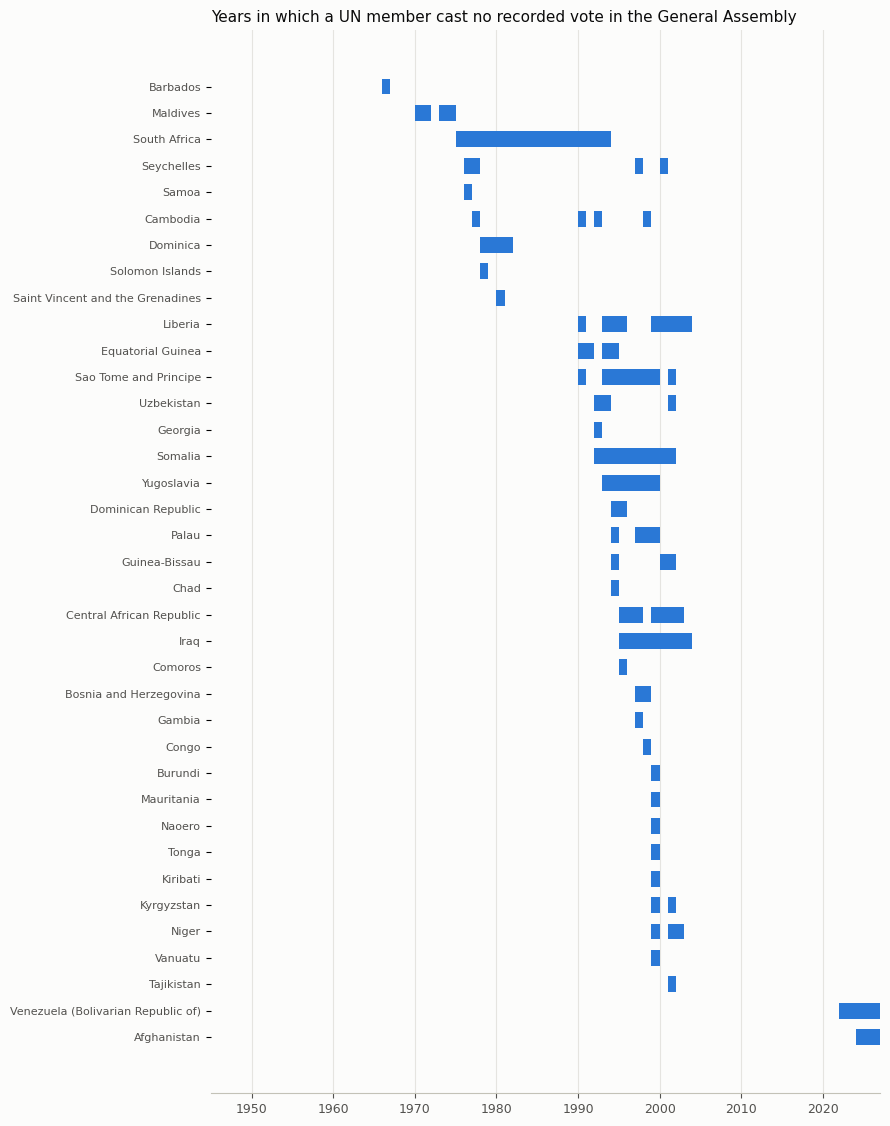

In [26]:
import matplotlib.pyplot as plt

order = stretches.groupby("country")["from_year"].min().sort_values(ascending=False).index
row = {country: i for i, country in enumerate(order)}

fig, ax = plt.subplots(figsize=(9, 0.28 * len(order) + 1))
ax.barh(
    [row[c] for c in stretches["country"]],
    stretches["to_year"] - stretches["from_year"] + 1,
    left=stretches["from_year"],
    height=0.6,
    color="#2a78d6",
)
ax.set_yticks(range(len(order)), order, fontsize=8, color="#52514e")
ax.tick_params(axis="x", colors="#52514e", labelsize=9)
ax.set_xlim(1945, pd.Timestamp.today().year + 1)
ax.grid(axis="x", color="#e5e4e0", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
ax.set_title("Years in which a UN member cast no recorded vote in the General Assembly",
             loc="left", fontsize=11, color="#0b0b0b")
fig.patch.set_facecolor("#fcfcfb")
ax.set_facecolor("#fcfcfb")
plt.tight_layout()
plt.show()


### 1g. Effect on the site's multilateral scatter

`app/features/multilateral_scatter.py` only plots countries with at least
`_MIN_VOTES_THRESHOLD = 10` votes cast in the selected resolutions. For one decade, which
members are left out, and why?


In [27]:
start, end = pd.Timestamp("1980-01-01"), pd.Timestamp("1989-12-31")

in_period = member_votes[member_votes["date"].between(start, end)]
cast = in_period.assign(cast=in_period["vote"] != "X").groupby("country_code")["cast"].sum()

dropped = cast[cast < 10].rename("votes_cast").to_frame()
dropped.insert(0, "country", dropped.index.map(names))
print(f"{len(dropped)} members excluded from the scatter for {start.year}–{end.year}:")
dropped


1 members excluded from the scatter for 1980–1989:


,country,votes_cast
country_code,,
ZAF,South Africa,0


### Headline cases

| Country | Silent | Likely cause | Status |
|---|---|---|---|
| South Africa | 1975–1993 | General Assembly rejected its delegation's credentials in 1974 over apartheid, excluding it from participation until 1994 | Well documented |
| Yugoslavia (FRY) | 1993–1999 | Resolution 47/1 (1992): the FRY could not automatically continue the former Yugoslavia's membership; admitted as a new member in 2000 | Well documented |
| Venezuela | 2022–present | Loss of vote for arrears under Article 19 | Likely; confirm against the Secretary-General's Article 19 communications |
| Somalia | 1992–2001 | No functioning central government after 1991 | Likely; confirm |
| Iraq | 1995–2003 | Possibly arrears during the sanctions period | To check |
| Afghanistan | 2024–present | Arrears, or the representation question after 2021 | To check |


### Next: classify the cause of each stretch

Each stretch needs a documented cause, using UN sources such as credentials committee reports
and the Secretary-General's communications on Article 19 arrears. Provisional categories:

- suspended or excluded from participation
- loss of vote for arrears (Article 19)
- no functioning or recognised government
- disputed seat or state succession
- new member without a delegation in place yet
- other

Two patterns to test: several stretches follow shortly after a small state's admission
(Barbados 1966, Seychelles and Samoa 1976, Dominica 1978, Palau 1997), the 1990s cases may
coincide with arrears or civil conflict, and the timeline (1f) shows a cluster of one-year
silences in 1999 (Burundi, Kiribati, Mauritania, Nauru, Niger, Tonga, Vanuatu and others),
which could point to a single wave of Article 19 suspensions.


In [1]:
# 


## Data and method references

- [GA export documentation](../data/GA/2025_07_23_ga_voting_md.md): UN Dag Hammarskjöld
  Library, General Assembly Voting Data, version 3, July 2025.
- [SC export documentation](../data/SC/2025_07_21_sc_voting_md.md): UN Dag Hammarskjöld
  Library, Security Council Voting Data, version 3, July 2025.
- [Current agreement implementation](../../app/un_data_stream/data/processor.py).
- [Hand-calculated agreement and consensus examples in the project tests](../../tests/unit/test_resolution_matrix.py).

The export dates identify the source versions, not the date coverage of every small sample.
No live source requests are made by this notebook.
